## BUSCO orthology and alignments

In [1]:
import os 
import pandas as pd 
import multiprocessing as mp
from Bio import SeqIO

In [1]:
annotated_genomes={"Aedes_aegypti" : "GCF_002204515.2", 
"Hermetia_illucens": "GCF_905115235.1", 
"Drosophila_melanogaster":	"GCF_000001215.4",
"Sitodiplosis_mosellana": "GCF_009176505.1",
"Contarinia_nasturtii": "GCF_009176525.2",
"Bradysia_odoriphaga":"GCA_016920775.1",
"Bradysia_coprophila":"GCF_014529535.2",
"Pseudolycoriella_hygida":"GCA_029228625.1",
"Lycoriella_ingenua":"GCA_965233655.1",
"Bradysia_impatiens":"GCA_965233325.1"}


In [4]:
!mkdir -p sciarid_species_tree
!mkdir -p sciarid_species_tree/BUSCO_proteins

In [13]:
!ls "/n/netscratch/extavour_lab/Everyone/Rishabh/ncbi_dataset/data/GCF_002204515.2"

genomic.gff  longest_isoform.fasta  protein.faa


In [14]:
import os
for x in annotated_genomes:
    if annotated_genomes[x] not in os.listdir("ncbi_dataset/data/"):
        c=f"/n/netscratch/extavour_lab/Everyone/Rishabh/ncbi_dataset/data/{annotated_genomes[x]}/longest_isoform.fasta"
        d=f"sciarid_species_tree/BUSCO_proteins/{x}.fasta"
        !cp "$c" "$d"
    else:
        if 'longest_isoform.faa' in os.listdir(f"ncbi_dataset/data/{annotated_genomes[x]}/"):
            
            c=f"ncbi_dataset/data/{annotated_genomes[x]}/longest_isoform.faa"
        elif 'longest_isoform.fasta' in os.listdir(f"ncbi_dataset/data/{annotated_genomes[x]}/"):
            c=f"ncbi_dataset/data/{annotated_genomes[x]}/longest_isoform.fasta"
        else:
            c=f"ncbi_dataset/data/{annotated_genomes[x]}/protein.faa"
        d=f"sciarid_species_tree/BUSCO_proteins/{x}.fasta"
        !cp "$c" "$d"

In [21]:
!mv BUSCO_outputs sciarid_species_tree/

In [31]:
def write_fasta(x):
    f=open(f"sciarid_species_tree/BUSCO_proteins/{species}.fasta","a")
    f.write(f">{x}\n")
    f.write(str(fasta[x].seq)+"\n")
    f.close()
    return 
    

In [32]:
def get_gene(x):
    return gff[gff[8].str.contains(x)].iloc[0,8].split(";gene=")[1].split(";")[0]

In [41]:
for species, xn in annotated_genomes.items():
    if 'GCF' in xn and f'{species}.fasta' not in os.listdir("BUSCO_proteins"):
        print(species)
        gff=pd.read_csv(f"ncbi_dataset/data/{xn}/genomic.gff",sep="\t",comment="#",header=None)
        
        input_file = open(f"ncbi_dataset/data/{xn}/protein.faa")
        fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
        dfl=pd.DataFrame(index=fasta.keys())
        for x in fasta:
            dfl.loc[x,"len"]=len(str(fasta[x].seq))
        num_processes = 89
        pool = mp.Pool(processes=num_processes)
    
        # Use the pool's map function to apply the get_data function to each element in td
        result = pool.map(get_gene, list(dfl.index))
        dfl.loc[:,"gene"]=result
        
        # Find the index of the row with the maximum length within each group
        idx = dfl.groupby('gene')['len'].idxmax()
    
        # Select rows based on the indices
        dfriso = dfl.loc[idx]
    
        pool = mp.Pool(processes=num_processes)
        l=list(dfriso.index)
        pool.map(write_fasta, l)
 

Bradysia_coprophila


In [1]:
%%bash 
## Diadocidia ferruginosa unannotated genome (family Diadocidiidae)
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/027/564/275/GCA_027564275.1_ASM2756427v1/GCA_027564275.1_ASM2756427v1_genomic.fna.gz
gunzip GCA_027564275.1_ASM2756427v1_genomic.fna.gz

--2026-06-28 09:59:38--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/027/564/275/GCA_027564275.1_ASM2756427v1/GCA_027564275.1_ASM2756427v1_genomic.fna.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.13, 130.14.250.12, 2607:f220:41e:250::10, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 124471361 (119M) [application/x-gzip]
Saving to: ‘GCA_027564275.1_ASM2756427v1_genomic.fna.gz’

     0K .......... .......... .......... .......... ..........  0%  438M 0s
    50K .......... .......... .......... .......... ..........  0%  502M 0s
   100K .......... .......... .......... .......... ..........  0% 3.70M 11s
   150K .......... .......... .......... .......... ..........  0%  123M 8s
   200K .......... .......... .......... .......... ..........  0% 3.71M 13s
   250K .......... .......... .......... .......... ..........  0%  119M 11s
   300K .......... .......... .......... .......... ..........  0%  131M 10s

In [4]:
%%bash 
## Mycetophila fungorum unannotated genome (family Mycetophilidae)
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/981/263/315/GCA_981263315.1_idMycFung1.hap1.1/GCA_981263315.1_idMycFung1.hap1.1_genomic.fna.gz
gunzip GCA_981263315.1_idMycFung1.hap1.1_genomic.fna.gz

--2026-06-29 15:12:13--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/981/263/315/GCA_981263315.1_idMycFung1.hap1.1/GCA_981263315.1_idMycFung1.hap1.1_genomic.fna.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.11, 130.14.250.10, 2607:f220:41e:250::7, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 61815879 (59M) [application/x-gzip]
Saving to: ‘GCA_981263315.1_idMycFung1.hap1.1_genomic.fna.gz’

     0K .......... .......... .......... .......... ..........  0% 2.18M 27s
    50K .......... .......... .......... .......... ..........  0% 12.6M 16s
   100K .......... .......... .......... .......... ..........  0% 4.93M 15s
   150K .......... .......... .......... .......... ..........  0%  129M 11s
   200K .......... .......... .......... .......... ..........  0% 3.87M 12s
   250K .......... .......... .......... .......... ..........  0% 90.7M 10s
   300K .......... .......... .......... .......... .........

In [16]:
!mkdir sciarid_species_tree/BUSCO_outputs

In [11]:
%%bash
##run busco on genome sequence of unanotated genome (Diadocidia ferruginosa)
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i "GCA_027564275.1_ASM2756427v1_genomic.fna" -l "BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10" -c 50 -m genome -f -o sciarid_species_tree/BUSCO_outputs/Diadocidia_ferruginosa --offline --metaeuk

2026-06-28 15:02:17 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 06/28/2026 15:02:17 *****
2026-06-28 15:02:17 INFO:	Configuring BUSCO with local environment
2026-06-28 15:02:17 INFO:	Running genome mode
2026-06-28 15:02:17 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/GCA_027564275.1_ASM2756427v1_genomic.fna
2026-06-28 15:02:17 INFO:	Using local lineages directory BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-06-28 15:02:18 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-06-28 15:02:18 INFO:	Running 1 job(s) on bbtools, starting at 06/28/2026 15:02:18
2026-06-28 15:02:20 INFO:	[bbtools]	1 of 1 task(s) completed
2026-06-28 15:02:20 INFO:	Running 1 job(s) on metaeuk, starting at 06/28/2026 15:02:20
2026-06-28 15:09:08 INFO:	[metaeuk]	1 of 1 task(s) completed
2026-06-28 15:09:14 INFO:	***** Run HMMER on gene sequences *****
2026-06-28 15:09:14 INFO:	Running 3285 job(s) on hmmsea

In [1]:
%%bash
##run busco on genome sequence of unanotated genome (Mycetophila fungorum)
singularity exec /cvmfs/singularity.galaxyproject.org/b/u/busco:5.7.1--pyhdfd78af_0 busco -i "GCA_981263315.1_idMycFung1.hap1.1_genomic.fna" -l "BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10" -c 70 -m genome -f -o sciarid_species_tree/BUSCO_outputs/Mycetophila_fungorum --offline --metaeuk

2026-06-29 20:57:27 INFO:	***** Start a BUSCO v5.7.1 analysis, current time: 06/29/2026 20:57:27 *****
2026-06-29 20:57:27 INFO:	Configuring BUSCO with local environment
2026-06-29 20:57:27 INFO:	Running genome mode
2026-06-29 20:57:27 INFO:	'Force' option selected; overwriting previous results directory
2026-06-29 20:57:29 INFO:	Input file is /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/GCA_981263315.1_idMycFung1.hap1.1_genomic.fna
2026-06-29 20:57:29 INFO:	Using local lineages directory BUSCO_phylogenomics/busco_downloads/lineages/diptera_odb10
2026-06-29 20:57:30 INFO:	Running BUSCO using lineage dataset diptera_odb10 (eukaryota, 2024-01-08)
2026-06-29 20:57:30 INFO:	Running 1 job(s) on bbtools, starting at 06/29/2026 20:57:30
2026-06-29 20:57:32 INFO:	[bbtools]	1 of 1 task(s) completed
2026-06-29 20:57:32 INFO:	Running 1 job(s) on metaeuk, starting at 06/29/2026 20:57:32
2026-06-29 21:48:10 INFO:	[metaeuk]	1 of 1 task(s) completed
2026-06-29 21:48:22 INFO:	

In [71]:
!cp ncbi_dataset/data/GCA_029228625.1/protein.faa 'sciarid_species_tree/BUSCO_proteins/Pseudolycoriella_hygida.fasta'

In [17]:
!cp ncbi_dataset/data/GCA_016920775.1/protein.faa 'sciarid_species_tree/BUSCO_proteins/Bradysia_odoriphaga.fasta'

In [19]:
##assumes BUSCO dipteran set present
for x in annotated_genomes.keys():
     if x not in os.listdir("sciarid_species_tree/BUSCO_outputs"):
         print(x)
         !sbatch scripts/run_busco.sh "$x"
 
    

Aedes_aegypti
Submitted batch job 25382703
Drosophila_melanogaster
Submitted batch job 25382715
Sitodiplosis_mosellana
Submitted batch job 25382716
Contarinia_nasturtii
Submitted batch job 25382717
Bradysia_odoriphaga
Submitted batch job 25382720
Bradysia_coprophila
Submitted batch job 25382721
Pseudolycoriella_hygida
Submitted batch job 25382722
Lycoriella_ingenua
Submitted batch job 25382723
Bradysia_impatiens
Submitted batch job 25382724


In [22]:
!mv ../Bradysia_coprophila/BUSCO_phylogenomics/BUSCO_phylogenomics ./

In [2]:
### assumes conda install of https://github.com/jamiemcg/BUSCO_phylogenomics, commit id  1221a78
## run busco phylogenomics pipeline to get concatenated MSA (need to run in the BUSCO_phylogenomics conda environment from command line
!python3 BUSCO_phylogenomics/count_buscos.py -i sciarid_species_tree/BUSCO_outputs

29-06-2026 22:50:26	Looking for BUSCO runs in /net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs
29-06-2026 22:50:26	Found 12 BUSCO directories:
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs/Contarinia_nasturtii/run_diptera_odb10
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs/Lycoriella_ingenua/run_diptera_odb10
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs/Diadocidia_ferruginosa/run_diptera_odb10
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs/Aedes_aegypti/run_diptera_odb10
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_tree/BUSCO_outputs/Sitodiplosis_mosellana/run_diptera_odb10
/net/bos-nfsisilon/ifs/rc_labs/extavour_lab/rkapoor/Bradysia_HGT_2026/sciarid_species_

In [121]:
!mkdir sciarid_species_tree
### assumes conda install of https://github.com/jamiemcg/BUSCO_phylogenomics, commit id  1221a78
!sh scripts/run_busco_phylogenomics.sh

## Uncalibrated ML tree inference

In [9]:
!sbatch scripts/iqtree_partition.sh

Submitted batch job 26250543


In [2]:
!sbatch scripts/iqtree_no_partition.sh

Submitted batch job 25999927


## Approximate gamma rate distribution parameters from tree height and approximate dipteran TMRCA

In [2]:
import ete3
from ete3 import Tree

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:

tree_path = "sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/partition.treefile"
# Load the tree
t = Tree(tree_path, format=1)
outgroup=[a for a in t.get_leaves() if a.name=='Aedes_aegypti'][0]
t.set_outgroup(outgroup)
print(t)



   /-Aedes_aegypti
  |
  |      /-Hermetia_illucens
  |   /-|
  |  |   \-Drosophila_melanogaster
--|  |
  |  |               /-Lycoriella_ingenua
  |  |            /-|
  |  |           |  |   /-Bradysia_impatiens
  |  |           |   \-|
   \-|         /-|     |   /-Bradysia_coprophila
     |        |  |      \-|
     |        |  |         \-Bradysia_odoriphaga
     |      /-|  |
     |     |  |   \-Pseudolycoriella_hygida
     |   /-|  |
     |  |  |   \-Diadocidia_ferruginosa
     |  |  |
      \-|   \-Mycetophila_fungorum
        |
        |   /-Contarinia_nasturtii
         \-|
            \-Sitodiplosis_mosellana


In [ ]:
t=Tree("(Aedes_aegypti,((Hermetia_illucens,Drosophila_melanogaster),(((Lycoriella_ingenua,Bradysia_impatiens,Bradysia_coprophila,Bradysia_odoriphaga,Pseudolycoriella_hygida),Diadocidia_ferruginosa),Mycetophila_fungorum),(Contarinia_nasturtii,Sitodiplosis_mosellana)));")
print(t)

In [4]:

tree_path = "sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/no_partition.treefile"
# Load the tree
t = Tree(tree_path, format=1)
outgroup=[a for a in t.get_leaves() if a.name=='Aedes_aegypti'][0]
t.set_outgroup(outgroup)
print(t)



   /-Aedes_aegypti
  |
  |      /-Hermetia_illucens
  |   /-|
  |  |   \-Drosophila_melanogaster
--|  |
  |  |               /-Lycoriella_ingenua
  |  |            /-|
  |  |           |  |   /-Bradysia_impatiens
  |  |           |   \-|
   \-|         /-|     |   /-Bradysia_coprophila
     |        |  |      \-|
     |        |  |         \-Bradysia_odoriphaga
     |      /-|  |
     |     |  |   \-Pseudolycoriella_hygida
     |   /-|  |
     |  |  |   \-Diadocidia_ferruginosa
     |  |  |
      \-|   \-Mycetophila_fungorum
        |
        |   /-Contarinia_nasturtii
         \-|
            \-Sitodiplosis_mosellana


In [7]:
t.write(format=9)

'(Aedes_aegypti,((Hermetia_illucens,Drosophila_melanogaster),(((((Lycoriella_ingenua,(Bradysia_impatiens,(Bradysia_coprophila,Bradysia_odoriphaga))),Pseudolycoriella_hygida),Diadocidia_ferruginosa),Mycetophila_fungorum),(Contarinia_nasturtii,Sitodiplosis_mosellana))));'

In [5]:
tmrca=250
time_unit=100
group=[a for a in t.get_leaves() if a.name=='Bradysia_coprophila'][0]
mean_rate=group.get_distance(t.get_tree_root())/(tmrca/time_unit)
alpha=2
beta = alpha / mean_rate
print(alpha, beta)

2 7.829914031603744


## MCMCtree time calibration
Using approximate likelihood

In [10]:
from Bio import AlignIO

In [12]:
from Bio import AlignIO
from Bio.Align import MultipleSeqAlignment
from Bio.SeqRecord import SeqRecord

# Read the alignment
alignment = AlignIO.read("sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/SUPERMATRIX.fasta", "fasta")


# enforce uppercase and remove gap placeholders that PAML dislikes
cleaned = []
for rec in alignment:
    seq = str(rec.seq).upper().replace(".", "-")   # PAML prefers '-' for gaps
    cleaned.append(SeqRecord(rec.seq.__class__(seq), id=rec.id, description=""))

filtered_alignment = MultipleSeqAlignment(cleaned)

# Write RELAXED sequential PHYLIP (PAML-friendly)
AlignIO.write(filtered_alignment, "sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/fixed_SUPERMATRIX.phylip", "phylip-relaxed")


1

In [13]:
## make paml compatible
f=open("sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/fixed_SUPERMATRIX.phylip","r").readlines()
l=f[0]
k=l.strip()
k=k+' I\n'

fo=open("sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/fixed_SUPERMATRIX.phylip","w")
fo.write(k)
for x in f[1:]:
    fo.write(x)
fo.close()

In [14]:
##make character choices consistent with outputs
with open("sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/fixed_SUPERMATRIX.phylip", "r") as infile:
    data = infile.read()

data = data.replace("U", "X")

with open("sciarid_species_tree/BUSCO_alignment_iqtree/supermatrix/fixed_SUPERMATRIX.phylip", "w") as outfile:
    outfile.write(data)

In [1]:
##make directories for mcmc analysis, ensure mcmctree.ctl and mcmctree-outBV.ctl are present in each 
!mkdir -p sciarid_species_tree/MCMC_runs
!mkdir sciarid_species_tree/MCMC_runs/run_1
!mkdir sciarid_species_tree/MCMC_runs/run_2

In [2]:
!sbatch scripts/mcmctree.sh 1

Submitted batch job 35874111


In [3]:
!sbatch scripts/mcmctree.sh 2

Submitted batch job 35874118


In [1]:
## copy and paste parameters from posterior_out
run1="""t_n13          2.6192 ( 2.4840,  2.7042) ( 2.4940,  2.7103)  0.2163 (Jnode 22)
t_n14          2.5237 ( 2.3451,  2.6715) ( 2.3702,  2.6870)  0.3168 (Jnode 21)
t_n15          1.9861 ( 1.7699,  2.2028) ( 1.7723,  2.2048)  0.4325 (Jnode 20)
t_n16          2.1599 ( 1.9352,  2.3517) ( 1.9527,  2.3652)  0.4125 (Jnode 19)
t_n17          1.8715 ( 1.6061,  2.1057) ( 1.6181,  2.1153)  0.4973 (Jnode 18)
t_n18          1.6836 ( 1.4008,  1.9424) ( 1.4089,  1.9491)  0.5402 (Jnode 17)
t_n19          0.7322 ( 0.5115,  1.0010) ( 0.5003,  0.9845)  0.4843 (Jnode 16)
t_n20          0.5823 ( 0.3982,  0.8172) ( 0.3826,  0.7944)  0.4118 (Jnode 15)
t_n21          0.2706 ( 0.1717,  0.4143) ( 0.1613,  0.3959)  0.2346 (Jnode 14)
t_n22          0.1412 ( 0.0865,  0.2252) ( 0.0782,  0.2107)  0.1325 (Jnode 13)
t_n23          0.4100 ( 0.1782,  0.7496) ( 0.1488,  0.6947)  0.5458 (Jnode 12)
mu             0.2412 ( 0.1449,  0.3836) ( 0.1359,  0.3662)  0.2303
sigma2         0.2663 ( 0.1403,  0.4736) ( 0.1239,  0.4390)  0.3151
lnL          -10.5556 (-17.8300, -5.1640) (-17.1240, -4.7270) 12.3970"""

In [2]:
## copy and paste parameters from posterior_out
run2="""t_n13          2.6194 ( 2.4844,  2.7040) ( 2.4937,  2.7094)  0.2157 (Jnode 22)
t_n14          2.5236 ( 2.3464,  2.6714) ( 2.3675,  2.6830)  0.3155 (Jnode 21)
t_n15          1.9859 ( 1.7720,  2.2025) ( 1.7751,  2.2055)  0.4303 (Jnode 20)
t_n16          2.1573 ( 1.9268,  2.3514) ( 1.9450,  2.3652)  0.4202 (Jnode 19)
t_n17          1.8687 ( 1.5915,  2.1068) ( 1.6077,  2.1196)  0.5119 (Jnode 18)
t_n18          1.6813 ( 1.3873,  1.9445) ( 1.3957,  1.9505)  0.5548 (Jnode 17)
t_n19          0.7298 ( 0.4998,  1.0054) ( 0.4800,  0.9796)  0.4996 (Jnode 16)
t_n20          0.5803 ( 0.3892,  0.8205) ( 0.3720,  0.7962)  0.4242 (Jnode 15)
t_n21          0.2690 ( 0.1681,  0.4124) ( 0.1569,  0.3932)  0.2363 (Jnode 14)
t_n22          0.1403 ( 0.0847,  0.2238) ( 0.0787,  0.2123)  0.1336 (Jnode 13)
t_n23          0.4037 ( 0.1768,  0.7364) ( 0.1505,  0.6851)  0.5346 (Jnode 12)
mu             0.2410 ( 0.1445,  0.3825) ( 0.1328,  0.3631)  0.2303
sigma2         0.2672 ( 0.1405,  0.4736) ( 0.1232,  0.4387)  0.3155
lnL          -10.5683 (-17.8080, -5.1690) (-17.1040, -4.7130) 12.3910"""

In [3]:
import ast

t1 = []
for line in run1.split("\n"):  # Use "\n" for line separation
    line = line.strip()  # Remove leading and trailing whitespace
    if line:  # Check if line is not empty
        
        try:
            # Split the line and evaluate the second part
            parts = line.split()
            if len(parts) > 1:
                evaluated_value = ast.literal_eval(parts[1])  # Assuming the value is in the second position
               
                t1.append(evaluated_value)
            else:
                print("Not enough parts in line:", line)
        except (IndexError, ValueError) as e:
            print(f"Error processing line: {line} - {e}")
t2 = []
for line in run2.split("\n"):  # Use "\n" for line separation
    line = line.strip()  # Remove leading and trailing whitespace

    if line:  # Check if line is not empty
        
        try:
            # Split the line and evaluate the second part
            parts = line.split()
            if len(parts) > 1:
                evaluated_value = ast.literal_eval(parts[1])  # Assuming the value is in the second position
               
                t2.append(evaluated_value)
            else:
                print("Not enough parts in line:", line)
        except (IndexError, ValueError) as e:
            print(f"Error processing line: {line} - {e}")
# Now t1 contains the evaluated values


In [4]:
def percent_difference(a, b):
    return abs(a - b) / ((a + b) / 2) * 100
[percent_difference(a,b) for a,b in zip(t1,t2)]

[0.007635627839498262,
 0.0039625146117633955,
 0.010070493454178146,
 0.12044843880291457,
 0.14972461365701908,
 0.13670539986329275,
 0.32831737346100653,
 0.3440564252537419,
 0.5930318754633025,
 0.639431616341019,
 1.5484822416123811,
 0.08295313148071577,
 0.3373945641986924,
 -0.12024294756177221]

In [31]:
import plotly.express as px
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)

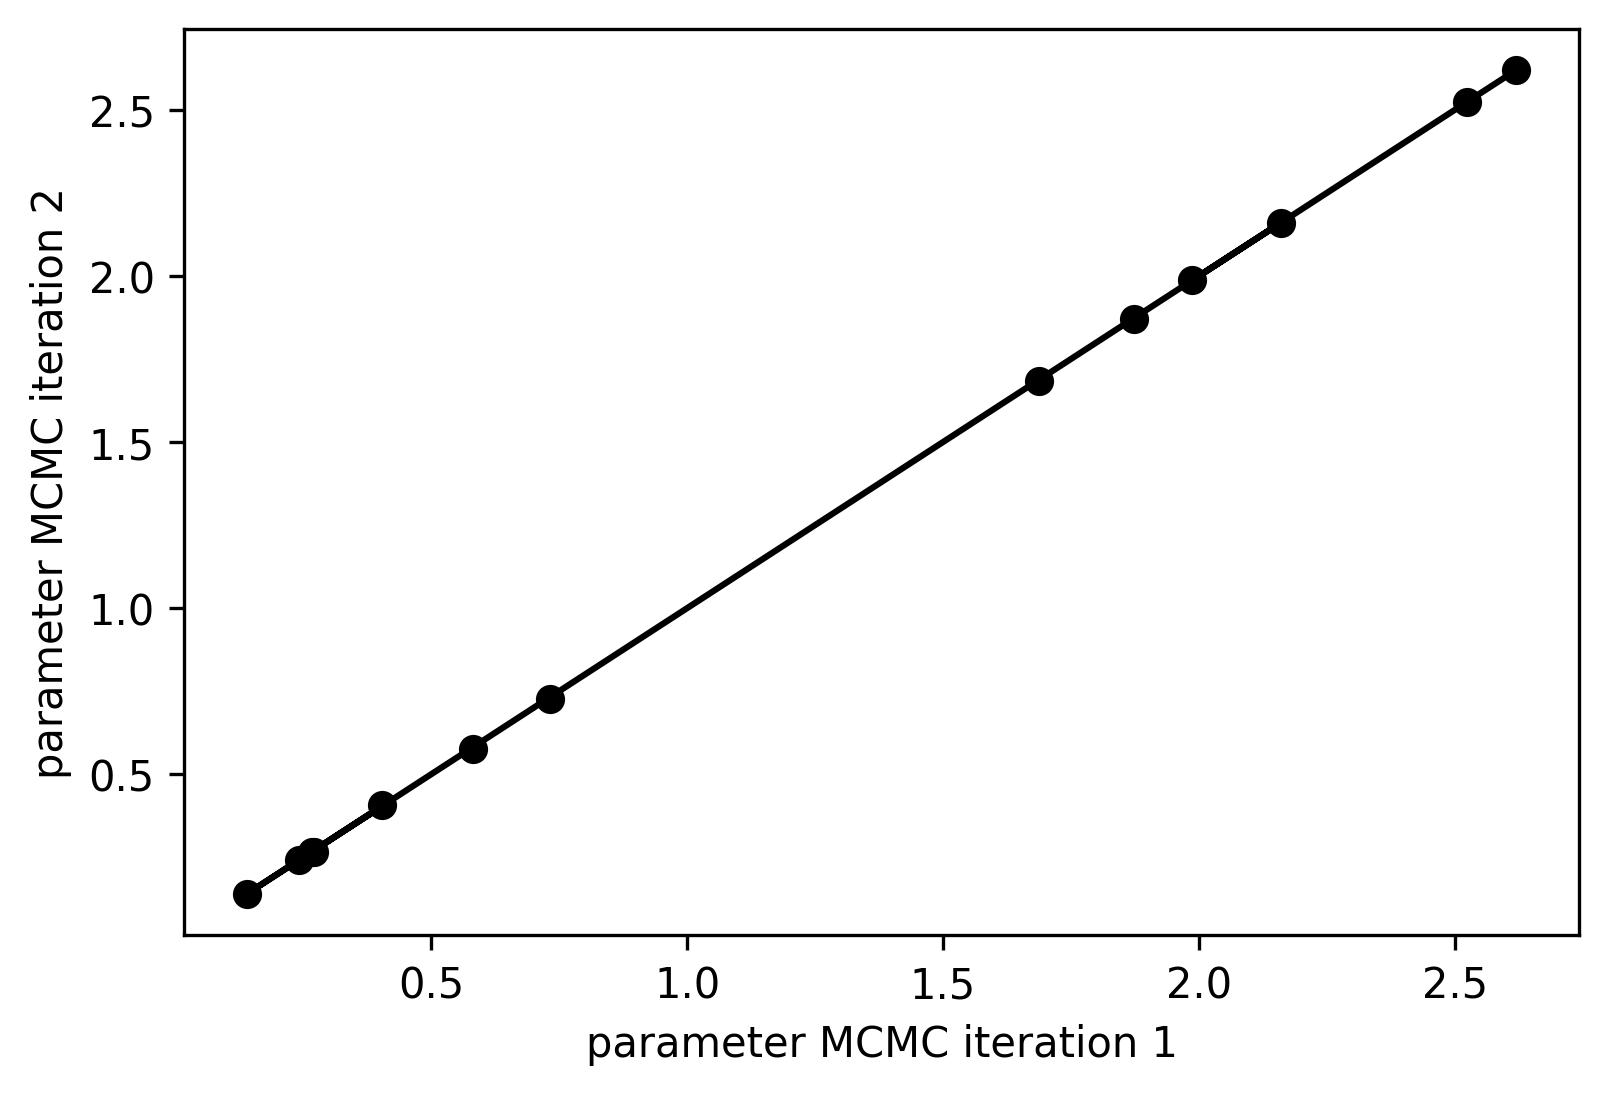

In [32]:
plt.scatter(t1,t2,color='black')
plt.xlabel('parameter MCMC iteration 1')
plt.ylabel('parameter MCMC iteration 2')
plt.plot(t1,t1,color='black')
plt.savefig('MCMC_convergence.svg',format='svg')


In [1]:
!mv sciarid_species_tree outputs/sciarid_species_tree